# Catalog visualization interface

This notebook is intentionally thin. Reusable logic belongs in `qq_helpers.py`; this file only sets paths, loads data, calls plotting functions, and saves outputs.

In [1]:
from pathlib import Path
import sys
import importlib

import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Folder where qq_helpers.py lives: this notebook lives in <QuickQuake>/examples/<name>/
HELPER_DIR = (Path.cwd() / "../../quickquake").resolve()

if str(HELPER_DIR) not in sys.path:
    sys.path.insert(0, str(HELPER_DIR))

import qq_helpers as h
importlib.reload(h)

print("helpers:", h.__file__)

helpers: /Users/evalzate/src/QuickQuake/quickquake/qq_helpers.py


## User settings

In [2]:
# Lines to edit: where your project's results are.
# Relative paths are relative to this notebook's folder (the example folder).
DATA_ROOT = Path("data").resolve()                           # the "data" folder next to QQ_driver.py
NAMEBASE = "GAMMA"                                           # same as location_namebase in QQ_driver.py

CATALOG_CSV = DATA_ROOT / f"merged/output/{NAMEBASE}_hypodd_catalog_qcfiltered.csv"
STATIONS_JSON = DATA_ROOT / f"merged/input/{NAMEBASE}_station_list.json"
IMAGE_DIR = h.ensure_dir(DATA_ROOT / "images")              # figures are saved next to the results

START = "2023-03-30T00:00:00Z"
END = "2023-03-31T00:00:00Z"

DEPTH_MAX = 15.0   # km; Aniakchak events are 0.5-9.6 km deep
EXAGG = 1.0
VIEW_ELEV = 10.0
VIEW_AZIM = 265.0

## Column mapping and data load

In [3]:
catc = h.CatalogCols(
    time="time",
    lat="latitude",
    lon="longitude",
    depth_km="depth_km",
    mag="magnitude",
)

stc = h.StationCols(
    station_id="station",
    lat="latitude",
    lon="longitude",
    elev_km="elev_km",
)

df_catalog = h.load_catalog_csv(CATALOG_CSV, catc=catc)
df_stations = h.load_stations_json(STATIONS_JSON)

print("Catalog shape:", df_catalog.shape)
print("Catalog columns:", df_catalog.columns.tolist())
print("Stations shape:", df_stations.shape)
print("Stations columns:", df_stations.columns.tolist())

display(df_catalog.head())
display(df_stations.head())

Catalog shape: (23, 7)
Catalog columns: ['time', 'latitude', 'longitude', 'depth_km', 'magnitude', 'event_id', 'pc_ratio_energy']
Stations shape: (15, 7)
Stations columns: ['station', 'component', 'elevation(m)', 'latitude', 'longitude', 'response', 'unit']


,time,latitude,longitude,depth_km,magnitude,event_id,pc_ratio_energy
0,2023-03-30 10:22:07.640000+00:00,56.907035,-158.048210,4.98,0.71,11,8.17
1,2023-03-30 10:24:13.230000+00:00,56.915316,-158.062256,3.36,1.35,12,79.02
2,2023-03-30 11:05:17.420000+00:00,56.903809,-158.031852,2.56,1.06,13,21.97
3,2023-03-30 11:29:21.410000+00:00,56.913957,-158.062354,1.98,0.84,15,21.42
4,2023-03-30 12:17:44.060000+00:00,56.873307,-158.048454,4.17,1.06,16,5.24


,station,component,elevation(m),latitude,longitude,response,unit
0,AK.R16K..BH,"[E, N, Z]",38.0,57.5673,-157.5742,"[628316000.0, 628316000.0, 628316000.0]",m/s
1,AK.S15K..HN,"[E, N, Z]",17.0,56.3058,-158.54,"[427894.0, 427894.0, 427894.0]",m/s**2
2,AV.ANNQ..BH,"[E, N, Z]",371.0,56.932754,-158.113103,"[301720000.0, 301720000.0, 301720000.0]",m/s
3,AV.ANNW..BH,"[E, N, Z]",812.0,56.96561,-158.2171,"[301720000.0, 301720000.0, 301720000.0]",m/s
4,AV.ANPK..BH,"[E, N, Z]",972.0,56.8409,-158.12839,"[301720000.0, 301720000.0, 301720000.0]",m/s


## Basic event-count time series

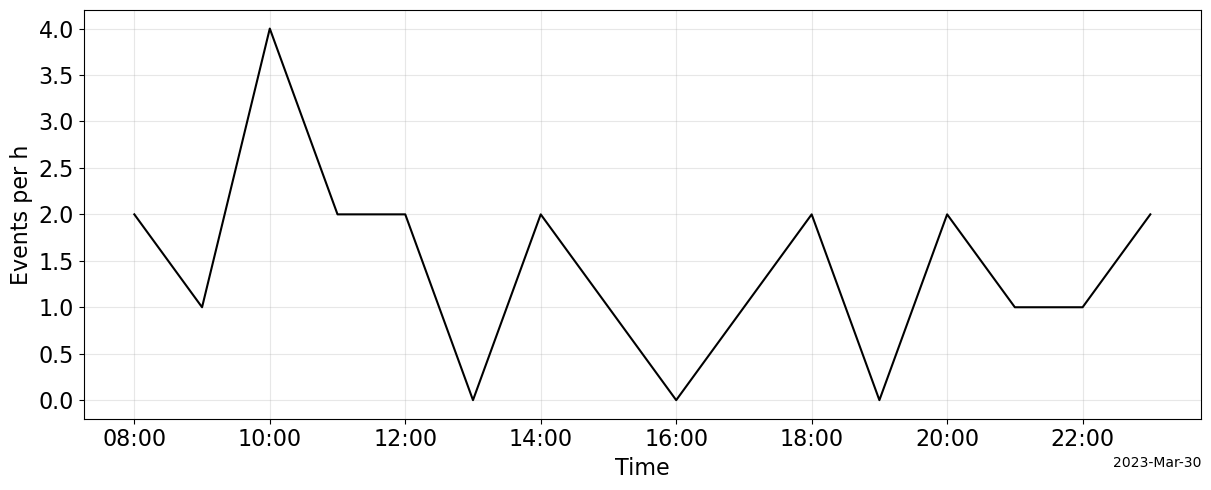

time
2023-03-30 08:00:00+00:00    2
2023-03-30 09:00:00+00:00    1
2023-03-30 10:00:00+00:00    4
2023-03-30 11:00:00+00:00    2
2023-03-30 12:00:00+00:00    2
Freq: h, dtype: int64

In [4]:
fig, ax, counts = h.plot_event_count_time(
    catalog=df_catalog,
    time_col=catc.time,
    start=START,
    end=END,
    freq="h",          # one bar per hour (the example covers 16 hours)
    figsize=(12, 5),
)

fig.savefig(IMAGE_DIR / "event_count_hourly.svg", bbox_inches="tight")
plt.show()

display(counts.head())

## 2D seismicity map

Seismicity map from 2023-03-30 to 2023-03-31 (Size = Magnitude | Color = Depth)


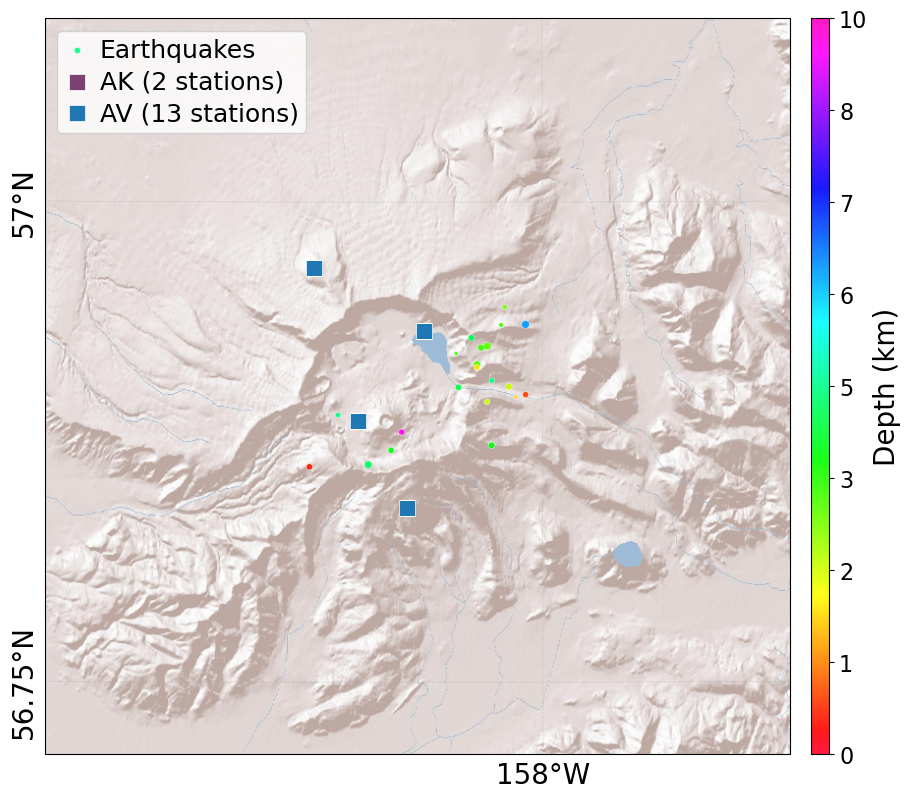

In [5]:
fig, ax = h.plot_mapview_seismicity(
    catalog=df_catalog,
    stations=df_stations,
    start=START,
    end=END,
    depth_vmin=0.0,
    depth_vmax=10.0,   # km; Aniakchak events are 0.5-9.6 km deep
    cmap_name="gist_rainbow",
    size_k=22.0,
    marker_min=6.0,
    plot_ellipse=False,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.5,
    step_lat=0.25,
    labelsize=20,
    figsize=(15, 8),
    savefig=False,
    dpi=600,
)

fig.savefig(IMAGE_DIR / "mapview_seismicity.svg", bbox_inches="tight")
plt.show()

## Basemap with stations only

Basemap from 2023-03-30 to 2023-03-31 without seismicity


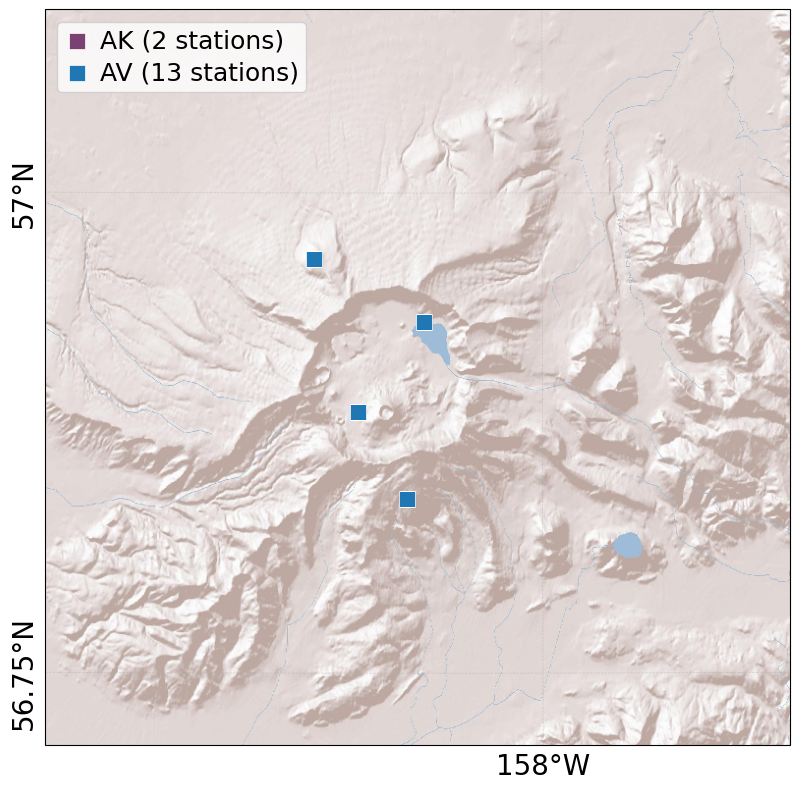

In [6]:
fig, ax = h.plot_mapview_basemap_stations(
    catalog=df_catalog,
    stations=df_stations,
    start=START,
    end=END,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.5,
    step_lat=0.25,
    labelsize=20,
    figsize=(15, 8),
    savefig=False,
    dpi=600,
)

fig.savefig(IMAGE_DIR / "mapview_stations_only.svg", bbox_inches="tight")
plt.show()

## 3D map colored by time

In [7]:
# 3D interactive visualization: topography + seismicity

import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"   # shows the figure in VS Code and in Jupyter

df_cat_plot = df_catalog.copy()
df_cat_plot["time"] = pd.to_datetime(df_cat_plot["time"], utc=True, errors="coerce")
df_cat_plot = df_cat_plot.dropna(subset=["time"]).copy()

start_dt = pd.to_datetime(START, utc=True)
end_dt = pd.to_datetime(END, utc=True)

df_cat_plot = df_cat_plot[
    (df_cat_plot["time"] >= start_dt) &
    (df_cat_plot["time"] <= end_dt)
].copy()

fig = h.plot_catalog_3d_topo_seismicity(
    catalog=df_cat_plot,
    catc=catc,
    mode="time",
    year=None,
    dem_res="15s",
    topo_exagg=3.0,
    topo_opacity=0.98,
    colorscale="Spectral",
    show=False,
    renderer="plotly_mimetype+notebook_connected",
    save_image=None,
    image_format="svg",
    image_width=1200,
    image_height=900,
    image_engine="kaleido",
)

fig.write_html(IMAGE_DIR / "catalog_3d_interactive.html", include_plotlyjs="cdn")

fig.show()   # uses pio.renderers.default, set at the top of this cell

Number of events after filters (time, depth<=15.0 km): 23


/Users/evalzate/src/QuickQuake/quickquake/qq_helpers.py:2018: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  df["_t_num"] = mdates.date2num(df["_t"].dt.to_pydatetime())


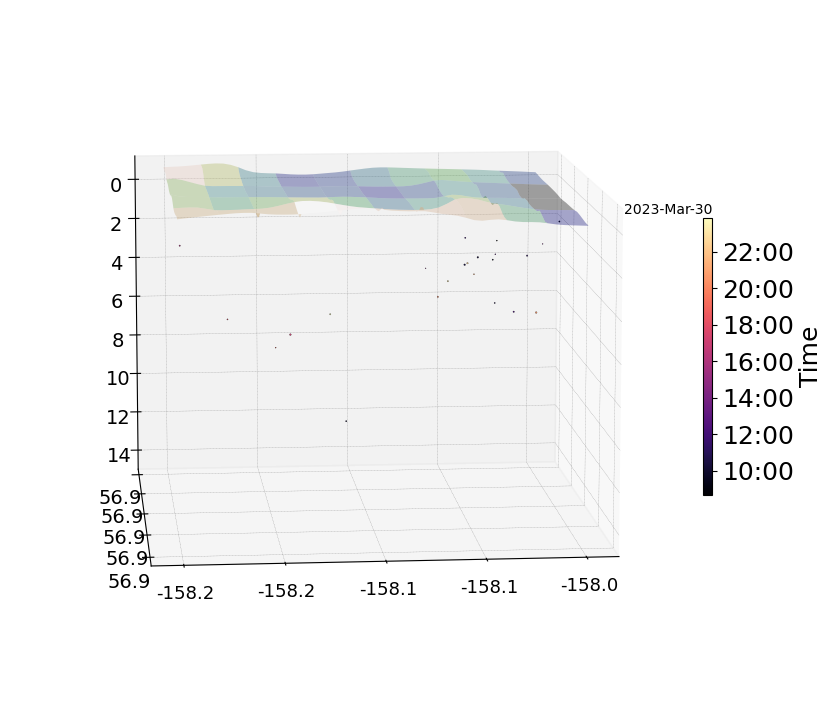

{'n_events': 23, 'region': [-158.221598, -158.015983, 56.862093, 56.945304], 'bounds': (-158.221598, -158.015983, 56.862093, 56.945304), 'dem_res': '15s', 'depth_max': 15.0, 'time_min': '2023-03-30 08:40:40.830000+00:00', 'time_max': '2023-03-30 23:51:45.960000+00:00'}


In [8]:
fig, ax, meta = h.plot_mapview3d_timecolor(
    catalog=df_catalog,
    start=START,
    end=END,
    depth_max=DEPTH_MAX,
    dem_res="15s",
    exagg=EXAGG,
    topo_cmap="gist_earth_r",
    quake_cmap="magma",
    size_k=1.0,
    topo_alpha=0.35,
    topo_stride=5,
    view_elev=VIEW_ELEV,
    view_azim=VIEW_AZIM,
    n_xticks=5,
    n_yticks=5,
    tick_fontsize=13,
    cbar_tick_fontsize=18,
    figsize=(12, 9),
    savefig=False,
    dpi=800,
    catc=catc,
)

fig.savefig(IMAGE_DIR / "mapview3d_timecolor.svg", bbox_inches="tight")
plt.show()

print(meta)

## Zoomed 2D seismicity map

Seismicity map from 2023-03-30 to 2023-03-31 (Size = Magnitude | Color = Depth)


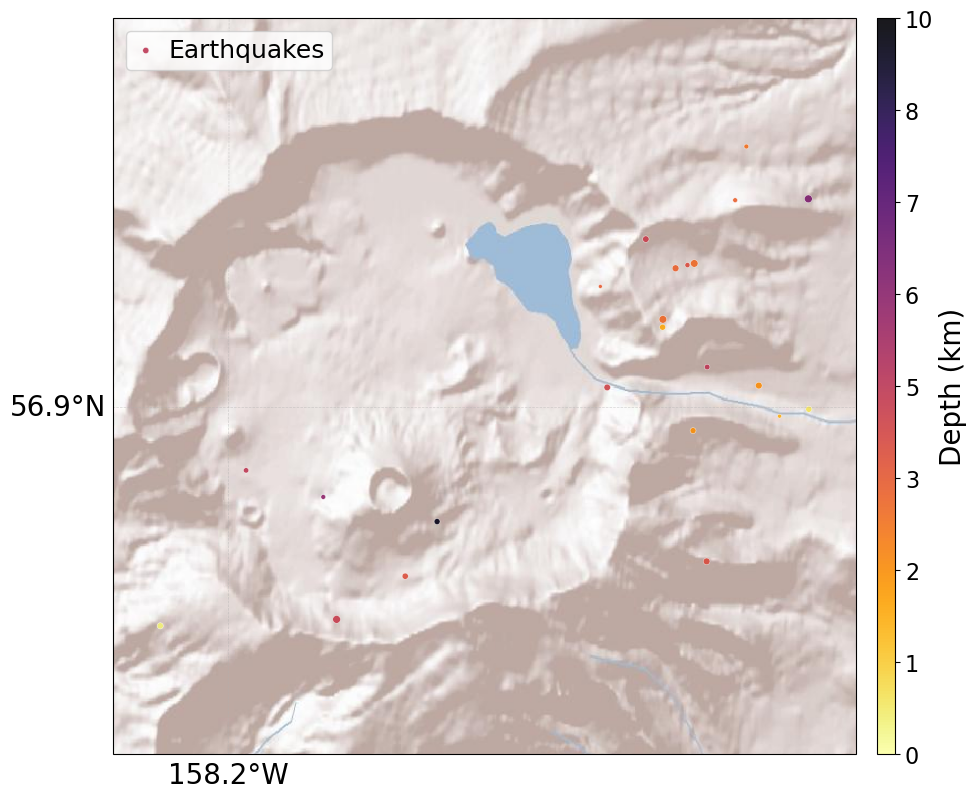

{'bounds': (-158.236393, -158.00118799999998, 56.839830000000006, 56.967567), 'center': (-158.1187905, 56.903698500000004)}


In [9]:
fig, ax, meta = h.plot_mapview_seismicity_zoom(
    catalog=df_catalog,
    start=START,
    end=END,
    depth_vmin=0.0,
    depth_vmax=10.0,
    cmap_name="inferno_r",
    size_k=22.0,
    marker_min=6.0,
    plot_ellipse=False,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.2,
    step_lat=0.1,
    labelsize=20,
    figsize=(15, 8),
    dpi=600,
    zoom_factor=3,
    show=False,
)

fig.savefig(IMAGE_DIR / "mapview_zoom.svg", bbox_inches="tight")
plt.show()

print(meta)

## Optional timeline with spans



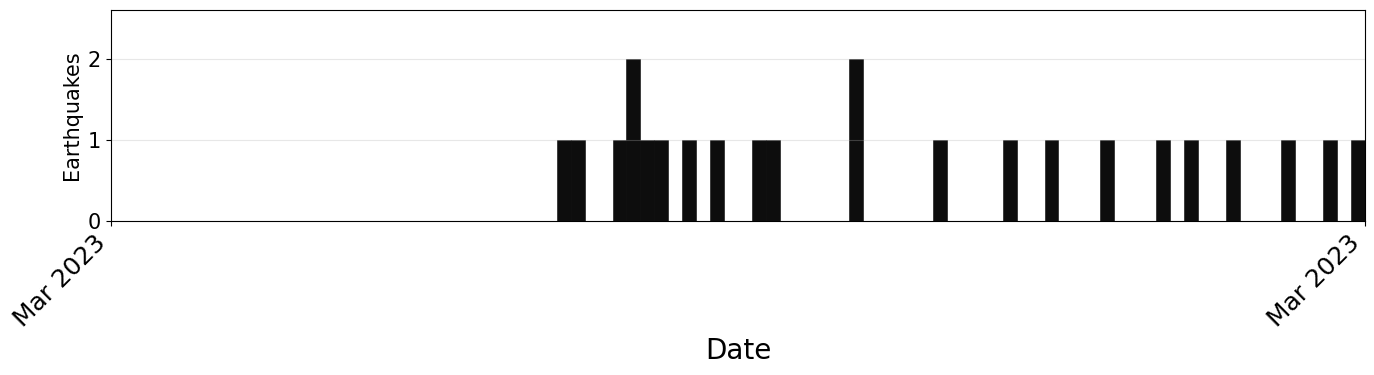

23


In [10]:
# Periods to shade on the timeline, as (start, end, label); empty for this example.
# e.g. spans = [("2021-07-29T12:00", "2021-07-29T14:00", "Swarm")]
spans = []

fig, ax, meta = h.plot_timeline_histogram(
    catalog=df_catalog,
    start=START,
    end=END,
    spans=spans,
    time_col=catc.time,
    fi_col="FI",  # if absent, helper uses EVENTS
    n_bins=90,
    figsize=(14, 4),
    show_legend=False,
    savefig=False,
    dpi=600,
)

fig.savefig(IMAGE_DIR / "timeline_histogram.svg", bbox_inches="tight")
plt.show()

print(meta["n_events"])

## Optional cross section

In [11]:
# Cross-section end points (lon, lat) and half-width of the swath (km): edit for your region.
# The values below are for Aniakchak, Alaska.
PROFILE = {
    "start_lon": -158.2729,
    "start_lat": 56.87708,
    "end_lon": -157.9812,
    "end_lat": 56.87708,
    "label_start": "C'",
    "label_end": "C",
    "swath_km": 5.0,
}

Seismicity map from 2023-03-30 to 2023-03-31 (Size = Magnitude | Color = Depth)


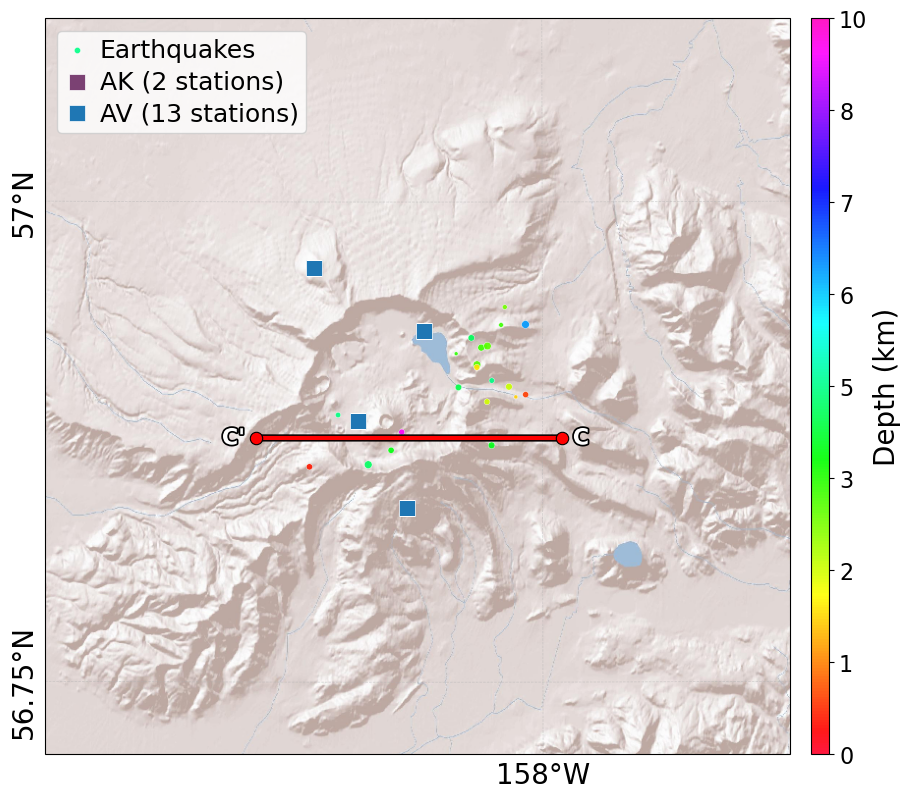

In [12]:
fig, ax = h.plot_mapview_seismicity(
    catalog=df_catalog,
    stations=df_stations,
    start=START,
    end=END,
    depth_vmin=0.0,
    depth_vmax=10.0,
    cmap_name="gist_rainbow",
    size_k=22.0,
    marker_min=6.0,
    plot_ellipse=False,
    relief_zoom=12,
    pad_lon=0.25,
    pad_lat=0.15,
    step_lon=0.5,
    step_lat=0.25,
    labelsize=20,
    figsize=(15, 8),
    savefig=False,   # important: save only after the profile line is added
    dpi=600,
)

h.add_profile_line(
    ax=ax,
    start_lon=PROFILE["start_lon"],
    start_lat=PROFILE["start_lat"],
    end_lon=PROFILE["end_lon"],
    end_lat=PROFILE["end_lat"],
    start_label=PROFILE["label_start"],
    end_label=PROFILE["label_end"],
    line_color="red",
    line_width=3.0,
    marker_size=80,
    fontsize=16,
)

fig.savefig(IMAGE_DIR / "mapview_seismicity_with_crosssection.pdf", bbox_inches="tight")
fig.savefig(IMAGE_DIR / "mapview_seismicity_with_crosssection.svg", bbox_inches="tight")
fig.savefig(IMAGE_DIR / "mapview_seismicity_with_crosssection.png", dpi=600, bbox_inches="tight")

plt.show()

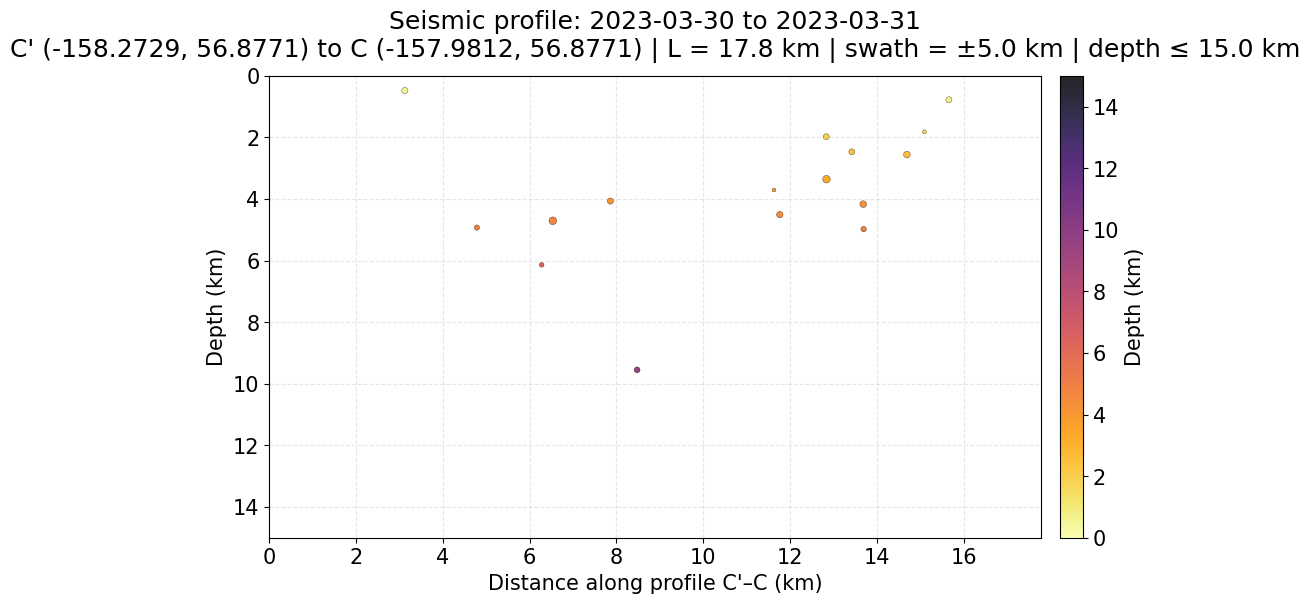

{'profile_length_km': 17.785637862067137, 'azimuth_deg': 89.87785051795235, 'n_events': 16, 'swath_km': 5.0, 'depth_max_plot': 15.0, 'start': (-158.2729, 56.87708), 'end': (-157.9812, 56.87708), 'distance_col': 'distance_km', 'across_col': 'across_km', 'projected_catalog':            lon        lat  depth   mag                         datetime  \
0  -158.048210  56.907035   4.98  0.71 2023-03-30 10:22:07.640000+00:00   
1  -158.062256  56.915316   3.36  1.35 2023-03-30 10:24:13.230000+00:00   
2  -158.031852  56.903809   2.56  1.06 2023-03-30 11:05:17.420000+00:00   
3  -158.062354  56.913957   1.98  0.84 2023-03-30 11:29:21.410000+00:00   
4  -158.048454  56.873307   4.17  1.06 2023-03-30 12:17:44.060000+00:00   
6  -158.025277  56.898494   1.82  0.37 2023-03-30 14:08:35.150000+00:00   
7  -158.082080  56.921033   3.71  0.34 2023-03-30 14:10:18.660000+00:00   
8  -158.221598  56.862093   0.48  0.90 2023-03-30 15:50:25.690000+00:00   
9  -158.165723  56.863249   4.71  1.41 2023-03-30 1

In [13]:
fig, ax, meta = h.plot_cross_section_seismicity(
    catalog=df_catalog,
    start=START,
    end=END,
    start_lon=PROFILE["start_lon"],
    start_lat=PROFILE["start_lat"],
    end_lon=PROFILE["end_lon"],
    end_lat=PROFILE["end_lat"],
    catc=catc,
    swath_km=PROFILE["swath_km"],
    depth_vmin=0.0,
    depth_vmax=DEPTH_MAX,
    depth_max_plot=DEPTH_MAX,
    cmap_name="inferno_r",
    size_k=22.0,
    marker_min=6.0,
    x_label_start=PROFILE["label_start"],
    x_label_end=PROFILE["label_end"],
    figsize=(12, 6),
)

fig.savefig(IMAGE_DIR / "cross_section_profile_C.svg", bbox_inches="tight")
plt.show()

print(meta)